# 01 - Data Engineer: Eksplorasi & Pembersihan Data  (Tahap 1)

**Peran:** Data Engineer - *pembersihan missing values & penanganan outlier*
**Dikerjakan oleh:** _(isi nama)_

### Cerita singkat tugasmu
Bayangkan data ini bahan makanan mentah. Kamu adalah orang yang **mencuci dan memilah** bahan sebelum dimasak (dianalisis) teman-temanmu.
Kalau kamu salah membersihkan, semua hasil analisis ikut salah. Jadi **setiap keputusan harus ada alasan statistik** yang kamu tulis.

### Yang harus selesai (dari panduan dosen, Tahap 1 a-c)
1. Skala pengukuran semua kolom
2. Jumlah missing values + penanganannya (dengan alasan)
3. Deteksi outlier dengan pagar IQR + **boxplot sebelum & sesudah**
4. Simpan **data bersih resmi** supaya 5 teman lain bisa memakainya

> Cara menjalankan: **Shift + Enter** per sel, dari atas ke bawah. Bagian bertanda ✏️ **ISI** wajib kamu tulis sendiri.

In [1]:
# ============ SETUP (jalankan sel ini PERTAMA) ============
# Satu-satunya yang boleh diubah: GITHUB_USER dan GITHUB_REPO (diisi sekali oleh Project Lead).
import os, sys, subprocess
GITHUB_USER = "Tur-ai"      # <- username GitHub pemilik repo
GITHUB_REPO = "udara-mobilitas-statsprob"     # <- nama repository
BRANCH = "main"

if "google.colab" in sys.modules:                      # kalau dijalankan di Google Colab
    PROYEK = "/content/proyek"
    if not os.path.exists(PROYEK):
        token = ""
        try:                                           # opsional: untuk repo PRIVATE (lihat docs/02_...)
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:
            pass
        url = f"https://{token}github.com/{GITHUB_USER}/{GITHUB_REPO}.git"
        r = subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, url, PROYEK],
                           capture_output=True, text=True)
        if r.returncode != 0:
            pesan = (r.stderr or "").replace(token.rstrip("@"), "***") if token else (r.stderr or "")
            raise RuntimeError("Gagal clone repo. Cek GITHUB_USER/GITHUB_REPO, atau lihat bagian "
                               "'Troubleshooting' di docs/02_panduan_github_colab.md\n" + pesan)
    else:
        subprocess.run(["git", "-C", PROYEK, "pull"], capture_output=True)   # ambil update terbaru
    os.chdir(PROYEK)
elif os.path.basename(os.getcwd()) == "notebooks":    # kalau dijalankan di Jupyter lokal
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from src.helpers import *
sns.set_theme(style="whitegrid", font_scale=1.0)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Setup selesai. Folder kerja:", os.getcwd())

Setup selesai. Folder kerja: d:\Kuliah\Semester 3\StatsProb\udara-mobilitas-statsprob


## 1. Muat data mentah

In [2]:
df = muat_data_mentah()
print(df.shape)
df.head()

(350, 9)


,ID_Observasi,Zona_Lokasi,Jenis_Hari,Jam_Sibuk,Volume_Kendaraan,Kecepatan_Angin_KmJ,Suhu_Celcius,Indeks_PM25,Status_Udara
0,OBS-12-0001,Pusat Kota,Hari Kerja,Tidak,623,35.0,27.7,35.8,Sedang
1,OBS-12-0002,Kawasan Kampus,Hari Kerja,Tidak,433,11.8,30.3,45.8,Sedang
2,OBS-12-0003,Pusat Kota,Hari Kerja,Tidak,670,16.2,25.2,54.3,Sedang
3,OBS-12-0004,Pusat Kota,Akhir Pekan,Tidak,487,3.8,27.9,51.5,Sedang
4,OBS-12-0005,Pinggiran,Hari Kerja,Tidak,273,6.6,29.6,28.8,Baik


## 2. Skala pengukuran (Tahap 1a)

Empat skala, dari yang paling "sederhana" ke paling "kaya informasi":

| Skala | Ciri | Contoh umum |
|---|---|---|
| **Nominal** | hanya nama kategori, tidak ada urutan | warna, jenis kelamin |
| **Ordinal** | ada urutan, tapi jarak antar kategori tidak pasti | Baik < Sedang < Buruk |
| **Interval** | ada urutan + jarak sama, tapi **nol bukan "tidak ada"** | suhu dalam °C |
| **Rasio** | seperti interval + **nol sungguhan** (0 = kosong) | tinggi badan, jumlah kendaraan |

Tabel di bawah adalah **usulan**. ✏️ **Tugasmu:** baca alasannya, pastikan kamu setuju & bisa menjelaskan ke dosen. Ubah kalau menurut tim ada yang keliru.

In [3]:
skala = pd.DataFrame({
    "Kolom": ["ID_Observasi", "Zona_Lokasi", "Jenis_Hari", "Jam_Sibuk", "Volume_Kendaraan",
              "Kecepatan_Angin_KmJ", "Suhu_Celcius", "Indeks_PM25", "Status_Udara"],
    "Skala": ["Nominal", "Nominal", "Nominal", "Nominal", "Rasio",
              "Rasio", "Interval", "Rasio", "Ordinal"],
    "Alasan": [
        "Hanya label pengenal baris; tidak ada urutan/hitungan",
        "3 kategori nama tempat tanpa urutan",
        "2 kategori tanpa urutan (biner)",
        "Ya/Tidak tanpa urutan (biner)",
        "Hasil hitungan; 0 kendaraan = benar-benar tidak ada kendaraan",
        "Ukuran fisik; 0 km/jam = tidak ada angin",
        "0 derajat C bukan 'tidak ada suhu' (nol bersifat sembarang); 20 C bukan 'dua kali' 10 C",
        "Konsentrasi; 0 = tidak ada partikel",
        "Ada urutan Baik < Sedang < Tidak Sehat, tapi jarak antar kelas tidak sama",
    ],
})
simpan_tabel(skala, "01_skala_pengukuran", index=False)
skala

[tersimpan] outputs/tables/01_skala_pengukuran.csv


,Kolom,Skala,Alasan
0,ID_Observasi,Nominal,Hanya label pengenal baris; tidak ada urutan/h...
1,Zona_Lokasi,Nominal,3 kategori nama tempat tanpa urutan
2,Jenis_Hari,Nominal,2 kategori tanpa urutan (biner)
3,Jam_Sibuk,Nominal,Ya/Tidak tanpa urutan (biner)
4,Volume_Kendaraan,Rasio,Hasil hitungan; 0 kendaraan = benar-benar tida...
5,Kecepatan_Angin_KmJ,Rasio,Ukuran fisik; 0 km/jam = tidak ada angin
6,Suhu_Celcius,Interval,0 derajat C bukan 'tidak ada suhu' (nol bersif...
7,Indeks_PM25,Rasio,Konsentrasi; 0 = tidak ada partikel
8,Status_Udara,Ordinal,"Ada urutan Baik < Sedang < Tidak Sehat, tapi j..."


## 3. Missing values (Tahap 1b)

**Missing value** = sel kosong (data tidak tercatat). Kita hitung dulu berapa banyak dan di mana.

In [4]:
tabel_missing = pd.DataFrame({
    "Jumlah_Kosong": df.isna().sum(),
    "Persen": (df.isna().mean() * 100).round(2),
})
simpan_tabel(tabel_missing, "01_missing_values")
tabel_missing

[tersimpan] outputs/tables/01_missing_values.csv


,Jumlah_Kosong,Persen
ID_Observasi,0,0.00
Zona_Lokasi,0,0.00
Jenis_Hari,0,0.00
Jam_Sibuk,0,0.00
Volume_Kendaraan,0,0.00
Kecepatan_Angin_KmJ,3,0.86
Suhu_Celcius,0,0.00
Indeks_PM25,3,0.86
Status_Udara,0,0.00


In [5]:
# Baris mana saja yang punya sel kosong?
df[df.isna().any(axis=1)]

,ID_Observasi,Zona_Lokasi,Jenis_Hari,Jam_Sibuk,Volume_Kendaraan,Kecepatan_Angin_KmJ,Suhu_Celcius,Indeks_PM25,Status_Udara
34,OBS-12-0035,Pusat Kota,Hari Kerja,Tidak,592,4.0,31.6,NaN,Sedang
80,OBS-12-0081,Pusat Kota,Hari Kerja,Ya,643,NaN,28.2,69.5,Tidak Sehat
88,OBS-12-0089,Kawasan Kampus,Hari Kerja,Ya,465,6.6,29.4,NaN,Tidak Sehat
124,OBS-12-0125,Pinggiran,Akhir Pekan,Tidak,159,NaN,25.8,21.4,Baik
134,OBS-12-0135,Kawasan Kampus,Hari Kerja,Ya,352,5.6,29.8,NaN,Sedang
159,OBS-12-0160,Pusat Kota,Hari Kerja,Ya,550,NaN,28.4,53.1,Sedang


### Keputusan penanganan (dengan alasan statistik)

Ada dua kolom bermasalah: `Indeks_PM25` dan `Kecepatan_Angin_KmJ`. Pilihan umum:

| Opsi | Kapan cocok |
|---|---|
| **Hapus baris** | kosongnya sedikit (<5%) dan acak; atau kolomnya adalah variabel yang mau diprediksi |
| **Isi dengan rata-rata** | data kira-kira simetris, tanpa outlier |
| **Isi dengan median** | data miring (skewed) atau ada outlier, karena median tahan terhadap nilai ekstrem |

**Usulan default:**
- `Indeks_PM25` -> **hapus baris**. Alasan: ini variabel utama/yang diprediksi di regresi. Kalau nilainya "ditebak" (diimputasi), kita memasukkan angka karangan ke variabel yang sedang kita teliti; selain itu hanya sedikit baris (<1%) yang hilang.
- `Kecepatan_Angin_KmJ` -> **isi dengan median**. Alasan: distribusinya miring ke kanan (ada angin kencang), jadi median lebih mewakili dari mean. Baris tetap terjaga.

✏️ **ISI:** setuju atau mau ganti? Tulis alasan tim di sel markdown di bawah sebelum lanjut.

✏️ **ISI - Keputusan & alasan tim:** _(tulis di sini; contoh: "Kami menghapus 3 baris PM2.5 kosong karena ... dan mengisi 3 sel angin dengan median (...) karena ...")_

In [6]:
# Cek skewness dulu sebagai bukti memilih median vs mean
print("Skewness angin :", round(df["Kecepatan_Angin_KmJ"].skew(), 2), "(positif = miring ke kanan)")
print("Mean angin     :", round(df["Kecepatan_Angin_KmJ"].mean(), 2))
print("Median angin   :", round(df["Kecepatan_Angin_KmJ"].median(), 2))

Skewness angin : 1.24 (positif = miring ke kanan)
Mean angin     : 10.05
Median angin   : 8.7


In [7]:
df_awal = df.copy()                       # simpan salinan data mentah untuk boxplot 'SEBELUM'
n_awal = len(df)

# 1) PM2.5 kosong -> hapus baris
df = df.dropna(subset=["Indeks_PM25"]).copy()

# 2) Angin kosong -> isi median
median_angin = df["Kecepatan_Angin_KmJ"].median()
df["Kecepatan_Angin_KmJ"] = df["Kecepatan_Angin_KmJ"].fillna(median_angin)

print("Baris awal :", n_awal)
print("Baris kini :", len(df))
print("Sisa kosong:", int(df.isna().sum().sum()))

Baris awal : 350
Baris kini : 347
Sisa kosong: 0


## 4. Cek konsistensi data (bonus penting)

`Status_Udara` seharusnya **sesuai** dengan `Indeks_PM25`. Dari data terlihat aturannya:
**<= 35 = Baik, 35-65 = Sedang, > 65 = Tidak Sehat**.
Kalau ada baris yang bertentangan, hampir pasti itu **salah input**, bukan kejadian nyata.

In [8]:
print(df_awal.groupby("Status_Udara")["Indeks_PM25"].agg(["min", "max", "count"]))
df["Status_harusnya"] = df["Indeks_PM25"].map(status_dari_pm25)
tidak_cocok = df[df["Status_harusnya"] != df["Status_Udara"]]
print("\nBaris yang Status_Udara-nya TIDAK cocok dengan nilai PM2.5:", len(tidak_cocok))
tidak_cocok

               min    max  count
Status_Udara                    
Baik           5.0  280.5    127
Sedang        35.1  245.0    193
Tidak Sehat   65.6   77.9     27

Baris yang Status_Udara-nya TIDAK cocok dengan nilai PM2.5: 2


,ID_Observasi,Zona_Lokasi,Jenis_Hari,Jam_Sibuk,Volume_Kendaraan,Kecepatan_Angin_KmJ,Suhu_Celcius,Indeks_PM25,Status_Udara,Status_harusnya
120,OBS-12-0121,Pinggiran,Akhir Pekan,Tidak,240,18.6,28.7,280.5,Baik,Tidak Sehat
314,OBS-12-0315,Pusat Kota,Hari Kerja,Tidak,646,20.8,31.2,245.0,Sedang,Tidak Sehat


Lihat kolom `Indeks_PM25`: ada nilai ratusan (misal 245 dan 280) padahal statusnya "Baik"/"Sedang" - padahal nilai setinggi itu seharusnya "Tidak Sehat". Datanya saling bertentangan, jadi **kemungkinan besar salah ketik** (mis. titik desimal bergeser).

✏️ **ISI - Keputusan tim:** _(usulan default: hapus 2 baris ini karena nilai aslinya tidak bisa dipastikan. Tulis alasanmu di sini.)_

In [9]:
df_valid = df[df["Status_harusnya"] == df["Status_Udara"]].copy()
print("Baris dihapus karena tidak konsisten:", len(df) - len(df_valid))
df = df_valid.drop(columns="Status_harusnya")
print("Baris kini:", len(df))

Baris dihapus karena tidak konsisten: 2
Baris kini: 345


## 5. Deteksi outlier dengan pagar IQR (Tahap 1c)

**Outlier** = nilai yang "terlalu jauh" dari kebanyakan data. Aturan pagar IQR:
- Q1 = kuartil 1 (25% data di bawahnya), Q3 = kuartil 3 (75% data di bawahnya)
- IQR = Q3 - Q1
- **Batas bawah** = Q1 - 1.5 x IQR
- **Batas atas** = Q3 + 1.5 x IQR
- Nilai di luar kedua batas = dicurigai outlier

Kita hitung pada data **mentah (setelah missing dibereskan)** supaya outlier PM2.5 yang tadi dihapus tetap tercatat di tabel "sebelum".

In [10]:
# Data 'sebelum penanganan outlier' = data mentah tanpa baris kosong PM2.5 (angin diisi median)
sebelum = df_awal.dropna(subset=["Indeks_PM25"]).copy()
sebelum["Kecepatan_Angin_KmJ"] = sebelum["Kecepatan_Angin_KmJ"].fillna(median_angin)

baris = []
for kol in KOLOM_NUMERIK:
    q1, q3, iqr, bb, ba = batas_iqr(sebelum[kol])
    n_out = int(((sebelum[kol] < bb) | (sebelum[kol] > ba)).sum())
    baris.append([kol, q1, q3, iqr, bb, ba, n_out])
tabel_iqr = pd.DataFrame(baris, columns=["Variabel", "Q1", "Q3", "IQR", "Batas_Bawah", "Batas_Atas", "Jumlah_Outlier"]).round(2)
simpan_tabel(tabel_iqr, "01_outlier_iqr", index=False)
tabel_iqr

[tersimpan] outputs/tables/01_outlier_iqr.csv


,Variabel,Q1,Q3,IQR,Batas_Bawah,Batas_Atas,Jumlah_Outlier
0,Volume_Kendaraan,289.50,532.50,243.00,-75.00,897.00,0
1,Kecepatan_Angin_KmJ,5.50,13.00,7.50,-5.75,24.25,15
2,Suhu_Celcius,27.05,30.30,3.25,22.18,35.17,2
3,Indeks_PM25,29.90,54.15,24.25,-6.48,90.52,2


[tersimpan] outputs/figures/01_boxplot_sebelum.png


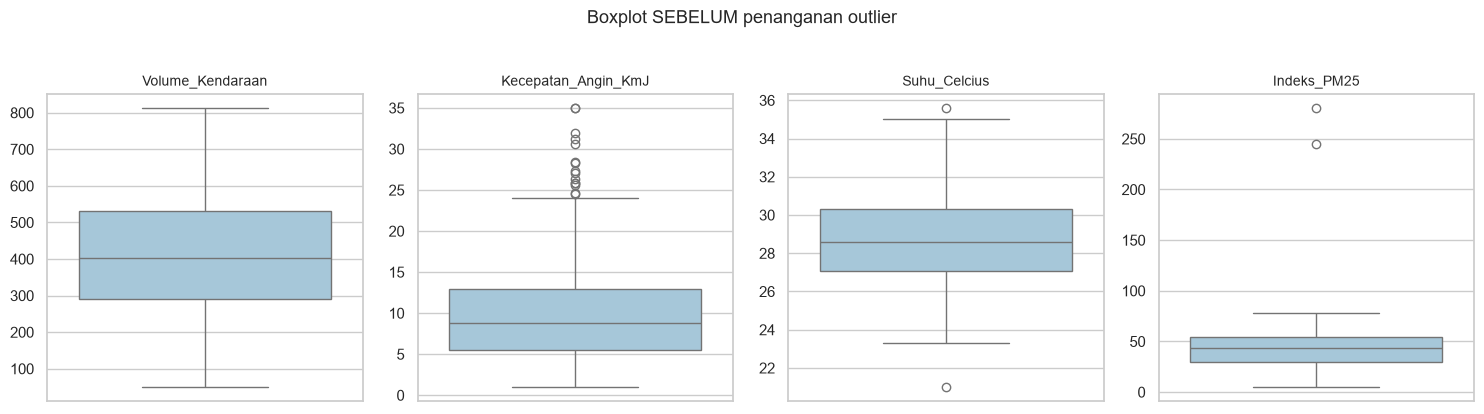

In [11]:
# Boxplot SEBELUM penanganan (4 variabel numerik, tiap variabel skala berbeda -> subplot terpisah)
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, kol in zip(axes, KOLOM_NUMERIK):
    sns.boxplot(y=sebelum[kol], ax=ax, color="#9ecae1")
    ax.set_title(kol, fontsize=10); ax.set_ylabel("")
fig.suptitle("Boxplot SEBELUM penanganan outlier", fontsize=13, y=1.03)
plt.tight_layout()
simpan_gambar(fig, "01_boxplot_sebelum")
plt.show()

Titik-titik di luar "kumis" boxplot = outlier menurut aturan IQR.

### Keputusan penanganan outlier

Tidak semua outlier harus dibuang! Tanyakan: **apakah ini kesalahan, atau kejadian nyata yang jarang?**

| Variabel | Temuan | Usulan penanganan | Alasan |
|---|---|---|---|
| `Indeks_PM25` | 2 nilai ekstrem (245 & 280.5) | **Sudah dihapus** di langkah 4 | Bertentangan dengan `Status_Udara` -> salah input |
| `Kecepatan_Angin_KmJ` | banyak nilai > batas atas | **Winsorizing** (nilai dipotong ke batas atas) | Angin kencang itu nyata (bukan salah input), tapi nilai ekstrem bisa "menarik" garis regresi. Winsorizing menjaga jumlah data |
| `Suhu_Celcius` | 2 nilai (21.0 dan 35.6) tipis di luar batas | **Winsorizing** | Hanya sedikit di luar batas; tetap masuk akal |
| `Volume_Kendaraan` | tidak ada | tidak diubah | - |

✏️ **ISI:** setuju? Boleh pilih strategi lain (mis. dibiarkan saja / dihapus), asal alasannya jelas. Ubah variabel `STRATEGI` di bawah.

In [12]:
# Pilihan per variabel: "biarkan", "winsor" (potong ke batas), atau "hapus" (buang baris)
STRATEGI = {
    "Volume_Kendaraan":    "biarkan",
    "Kecepatan_Angin_KmJ": "winsor",
    "Suhu_Celcius":        "winsor",
    "Indeks_PM25":         "biarkan",     # outlier-nya sudah ditangani di langkah 4
}

setelah = df.copy()
for kol, aksi in STRATEGI.items():
    # batas dihitung dari data 'sebelum' supaya konsisten dengan tabel di atas
    _, _, _, bb, ba = batas_iqr(sebelum[kol])
    if aksi == "winsor":
        n = int(((setelah[kol] < bb) | (setelah[kol] > ba)).sum())
        setelah[kol] = setelah[kol].clip(lower=bb, upper=ba)
        print(f"{kol}: {n} nilai dipotong ke [{bb:.2f}, {ba:.2f}]")
    elif aksi == "hapus":
        n = int(((setelah[kol] < bb) | (setelah[kol] > ba)).sum())
        setelah = setelah[(setelah[kol] >= bb) & (setelah[kol] <= ba)]
        print(f"{kol}: {n} baris dihapus")
print("\nBaris akhir:", len(setelah))

Kecepatan_Angin_KmJ: 15 nilai dipotong ke [-5.75, 24.25]
Suhu_Celcius: 2 nilai dipotong ke [22.18, 35.17]

Baris akhir: 345


[tersimpan] outputs/figures/01_boxplot_sesudah.png


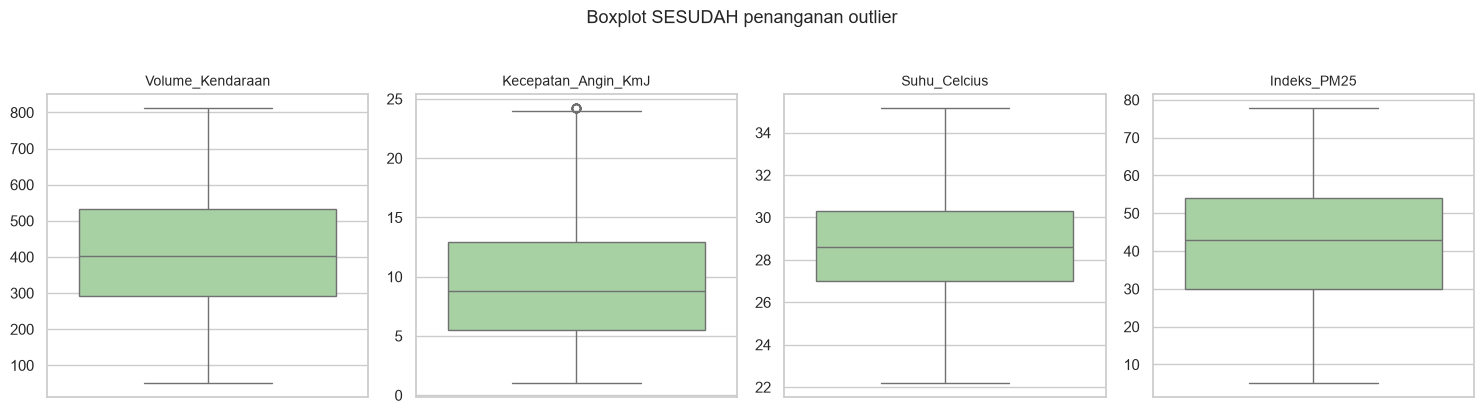

In [13]:
# Boxplot SESUDAH penanganan
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, kol in zip(axes, KOLOM_NUMERIK):
    sns.boxplot(y=setelah[kol], ax=ax, color="#a1d99b")
    ax.set_title(kol, fontsize=10); ax.set_ylabel("")
fig.suptitle("Boxplot SESUDAH penanganan outlier", fontsize=13, y=1.03)
plt.tight_layout()
simpan_gambar(fig, "01_boxplot_sesudah")
plt.show()

💡 **Kalau masih ada 1-2 titik di ujung boxplot (mis. di Kecepatan Angin) - itu wajar.** Setelah nilai ekstrem dipotong, Q1/Q3/IQR ikut sedikit berubah, sehingga pagar yang baru sedikit lebih ketat dari pagar lama. Cukup tulis di laporan: *"outlier ditangani satu kali menggunakan pagar IQR dari data awal; titik tersisa berada tepat di batas dan tidak ekstrem."* Jangan diulang terus-menerus sampai habis (itu praktik yang tidak dianjurkan).

## 6. Simpan DATA BERSIH RESMI

File inilah yang akan dipakai 5 temanmu. **Hanya Data Engineer yang boleh membuat/mengubahnya.**

In [14]:
bersih = setelah[["ID_Observasi", "Zona_Lokasi", "Jenis_Hari", "Jam_Sibuk", "Volume_Kendaraan",
                  "Kecepatan_Angin_KmJ", "Suhu_Celcius", "Indeks_PM25", "Status_Udara"]]
os.makedirs("data", exist_ok=True)
bersih.to_csv(FILE_BERSIH, index=False)
print("Disimpan:", FILE_BERSIH, "| baris:", len(bersih), "| kolom kosong:", int(bersih.isna().sum().sum()))

# Log ringkas untuk laporan (Bab Metodologi Pembersihan Data)
log = f'''LOG PEMBERSIHAN DATA - Kelompok {NO_KELOMPOK}
Baris awal                         : {n_awal}
Baris PM2.5 kosong (dihapus)       : {int(df_awal["Indeks_PM25"].isna().sum())}
Sel angin kosong (isi median {median_angin:.2f}) : {int(df_awal["Kecepatan_Angin_KmJ"].isna().sum())}
Baris status vs PM2.5 tidak konsisten (dihapus) : {len(tidak_cocok)}
Strategi outlier                   : {STRATEGI}
Baris akhir                        : {len(bersih)}
'''
simpan_teks(log, "01_log_pembersihan")
print(log)

Disimpan: data/Kelompok_12_data_bersih.csv | baris: 345 | kolom kosong: 0
[tersimpan] outputs/tables/01_log_pembersihan.txt
LOG PEMBERSIHAN DATA - Kelompok 12
Baris awal                         : 350
Baris PM2.5 kosong (dihapus)       : 3
Sel angin kosong (isi median 8.80) : 3
Baris status vs PM2.5 tidak konsisten (dihapus) : 2
Strategi outlier                   : {'Volume_Kendaraan': 'biarkan', 'Kecepatan_Angin_KmJ': 'winsor', 'Suhu_Celcius': 'winsor', 'Indeks_PM25': 'biarkan'}
Baris akhir                        : 345



## 7. Statistik singkat sebelum vs sesudah (bukti bahwa pembersihan berpengaruh)

In [15]:
bandingan = pd.concat({
    "Sebelum": sebelum[KOLOM_NUMERIK].agg(["count", "mean", "std", "min", "max"]).T,
    "Sesudah": bersih[KOLOM_NUMERIK].agg(["count", "mean", "std", "min", "max"]).T,
}, axis=1).round(2)
simpan_tabel(bandingan, "01_perbandingan_sebelum_sesudah")
bandingan

[tersimpan] outputs/tables/01_perbandingan_sebelum_sesudah.csv


Sebelum                              Sesudah                               
                      count    mean     std   min    max   count    mean     std    min     max
Volume_Kendaraan      347.0  408.24  164.17  50.0  813.0   345.0  408.04  163.90  50.00  813.00
Kecepatan_Angin_KmJ   347.0   10.08    6.47   1.0   35.0   345.0    9.84    5.91   1.00   24.25
Suhu_Celcius          347.0   28.67    2.43  21.0   35.6   345.0   28.67    2.42  22.18   35.17
Indeks_PM25           347.0   43.12   23.19   5.0  280.5   345.0   41.85   16.03   5.00   77.90

## 8. Unduh hasil lalu serahkan ke tim

Sel di bawah membuat 1 file ZIP berisi semua hasil Tahap 1 + data bersih. Unzip di laptop, lalu **upload ke GitHub** (lihat `docs/02_panduan_github_colab.md`, bagian "Mengunggah hasil").

⚠️ Setelah `data/Kelompok_12_data_bersih.csv` ada di GitHub, **kabari grup**: "Data bersih sudah ada, semua jalankan ulang notebook kalian."

In [16]:
unduh_hasil("hasil_01_data_engineer", file_tambahan=[FILE_BERSIH])

8 file dimasukkan ke hasil_01_data_engineer.zip:
  - data/Kelompok_12_data_bersih.csv
  - outputs/tables/01_skala_pengukuran.csv
  - outputs/tables/01_missing_values.csv
  - outputs/tables/01_outlier_iqr.csv
  - outputs/figures/01_boxplot_sebelum.png
  - outputs/figures/01_boxplot_sesudah.png
  - outputs/tables/01_log_pembersihan.txt
  - outputs/tables/01_perbandingan_sebelum_sesudah.csv
(bukan di Colab - ZIP ada di folder kerja)


'hasil_01_data_engineer.zip'

Dataset yang dipakai: data/Kelompok_12_Tema_B_Kualitas_Udara.csv
Daftar kolom: ['ID_Observasi', 'Zona_Lokasi', 'Jenis_Hari', 'Jam_Sibuk', 'Volume_Kendaraan', 'Kecepatan_Angin_KmJ', 'Suhu_Celcius', 'Indeks_PM25', 'Status_Udara']


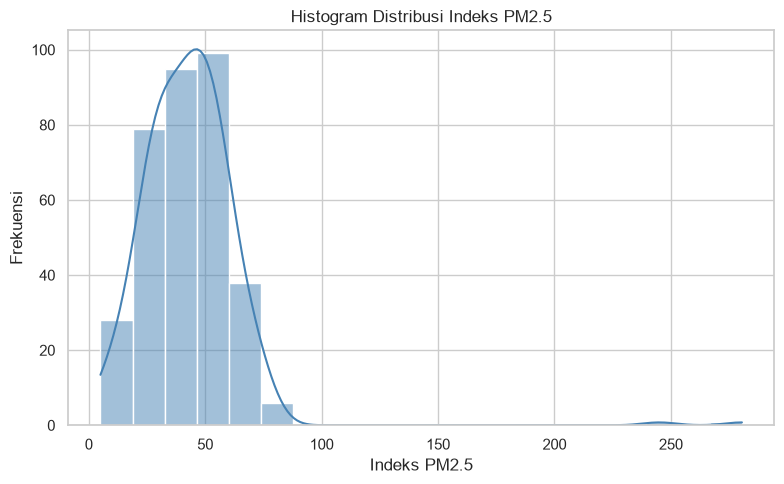

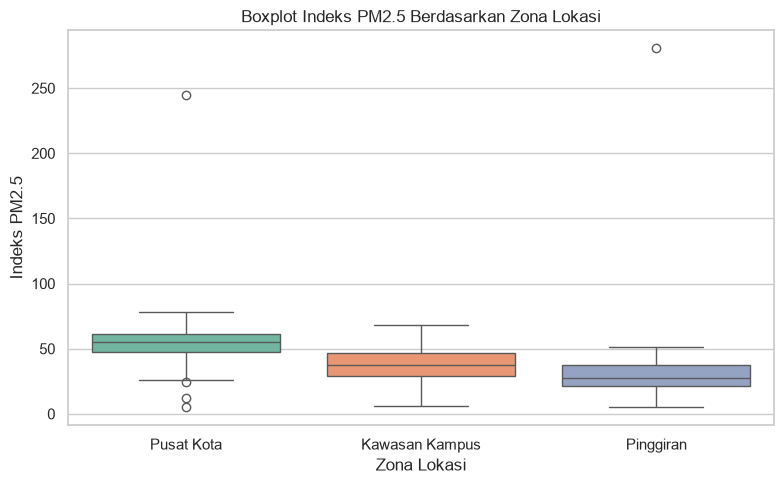

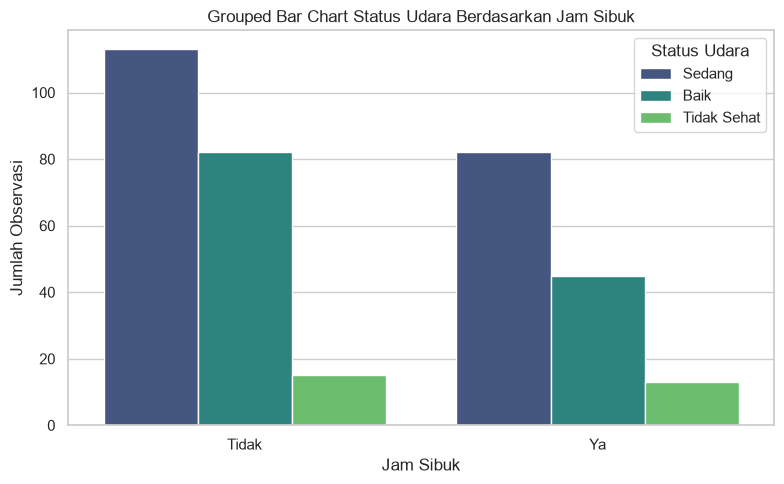

3 grafik tambahan berhasil disimpan ke outputs/figures/!


In [17]:
# === TAMBAHAN CHECKLIST 1d: 3 GRAFIK INFORMATIF MINGGU 1 ===
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("outputs/figures", exist_ok=True)

# Otomatis membaca dataset bersih di folder data/ (atau dataset utama jika belum terpisah)
clean_files = glob.glob("data/*[Cc][Ll][Ee][Aa][Nn]*.csv")
data_path = clean_files[0] if clean_files else "data/Kelompok_12_Tema_B_Kualitas_Udara.csv"
df_plot = pd.read_csv(data_path)
print("Dataset yang dipakai:", data_path)
print("Daftar kolom:", df_plot.columns.tolist())

# 1. Histogram (Distribusi Variabel Utama: Indeks_PM25)
plt.figure(figsize=(8, 5))
sns.histplot(df_plot["Indeks_PM25"], kde=True, bins=20, color="steelblue")
plt.title("Histogram Distribusi Indeks PM2.5")
plt.xlabel("Indeks PM2.5")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.savefig("outputs/figures/minggu1_1d_histogram_pm25.png", dpi=300)
plt.show()

# 2. Boxplot Perbandingan Kategori (Indeks_PM25 berdasarkan Zona_Lokasi)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_plot, x="Zona_Lokasi", y="Indeks_PM25", hue="Zona_Lokasi", palette="Set2", legend=False)
plt.title("Boxplot Indeks PM2.5 Berdasarkan Zona Lokasi")
plt.xlabel("Zona Lokasi")
plt.ylabel("Indeks PM2.5")
plt.tight_layout()
plt.savefig("outputs/figures/minggu1_1d_boxplot_pm25_zona.png", dpi=300)
plt.show()

# 3. Grouped Bar Chart (Status_Udara berdasarkan Jam_Sibuk)
plt.figure(figsize=(8, 5))
sns.countplot(data=df_plot, x="Jam_Sibuk", hue="Status_Udara", palette="viridis")
plt.title("Grouped Bar Chart Status Udara Berdasarkan Jam Sibuk")
plt.xlabel("Jam Sibuk")
plt.ylabel("Jumlah Observasi")
plt.legend(title="Status Udara")
plt.tight_layout()
plt.savefig("outputs/figures/minggu1_1d_grouped_bar_status_jamsibuk.png", dpi=300)
plt.show()

print("3 grafik tambahan berhasil disimpan ke outputs/figures/!")

### ✅ Checklist selesai (Data Engineer)
- [ ] Tabel skala pengukuran (9 kolom) ada & kamu bisa menjelaskan tiap alasan
- [ ] Jumlah missing + keputusan + alasan tertulis
- [ ] Tabel IQR + boxplot sebelum & sesudah tersimpan
- [ ] `Kelompok_12_data_bersih.csv` sudah di-upload ke folder `data/` di GitHub
- [ ] Log pembersihan tersimpan (untuk Technical Writer)
- [ ] Sudah memberi tahu grup bahwa data bersih tersedia